**Fecha de descarga de los datos: 16/09/2026.**

El dataset consolidado se descarga directo de la fuente oficial (Secretaría de Energía, datos.energia.gob.ar) en la celda siguiente. Se actualiza mensualmente, así que quien corra este notebook en otra fecha puede ver un número de filas distinto al reportado en este informe (421.046 filas al 16/09/2026). Los resultados y conclusiones de este análisis están calculados sobre esa versión del dato.

In [1]:
import pandas as pd

url = "http://datos.energia.gob.ar/dataset/c846e79c-026c-4040-897f-1ad3543b407c/resource/b5b58cdc-9e07-41f9-b392-fb9ec68b0725/download/produccin-de-pozos-de-gas-y-petrleo-no-convencional.csv"
df = pd.read_csv(url)

In [2]:
df.shape

(421046, 40)

In [3]:
list(df.columns)

['idempresa',
 'anio',
 'mes',
 'idpozo',
 'prod_pet',
 'prod_gas',
 'prod_agua',
 'iny_agua',
 'iny_gas',
 'iny_co2',
 'iny_otro',
 'tef',
 'vida_util',
 'tipoextraccion',
 'tipoestado',
 'tipopozo',
 'observaciones',
 'fechaingreso',
 'rectificado',
 'habilitado',
 'idusuario',
 'empresa',
 'sigla',
 'formprod',
 'profundidad',
 'formacion',
 'idareapermisoconcesion',
 'areapermisoconcesion',
 'idareayacimiento',
 'areayacimiento',
 'cuenca',
 'provincia',
 'coordenadax',
 'coordenaday',
 'tipo_de_recurso',
 'proyecto',
 'clasificacion',
 'subclasificacion',
 'sub_tipo_recurso',
 'fecha_data']

In [4]:
df.dtypes

,0
idempresa,object
anio,int64
mes,int64
idpozo,int64
prod_pet,float64
prod_gas,float64
prod_agua,float64
iny_agua,float64
iny_gas,float64
iny_co2,float64


In [5]:
df["sub_tipo_recurso"].value_counts()

,count
sub_tipo_recurso,
SHALE,224118
TIGHT,196476


In [6]:
df["formacion"].value_counts()

,count
formacion,
vaca muerta,216445
lajas,77407
mulichinco,34749
los molles,28011
magallanes,15605
precuyo,14603
quintuco,10958
punta rosada,9577
agrio,5671


In [7]:
df["anio"].value_counts().sort_index()

,count
anio,
2006,2368
2007,2442
2008,2280
2009,1698
2010,2038
2011,2599
2012,3640
2013,5184
2014,8777


In [8]:
df[df["anio"] == 2026]["mes"].value_counts().sort_index()

,count
mes,
1,4772
2,4814
3,4851
4,4903
5,4969
6,5015
7,5062


In [9]:
df.isna().sum()

,0
idempresa,0
anio,0
mes,0
idpozo,0
prod_pet,0
prod_gas,0
prod_agua,0
iny_agua,0
iny_gas,0
iny_co2,0


In [10]:
df.duplicated(subset=["idpozo", "anio", "mes"]).sum()

np.int64(0)

In [11]:
df["sigla"].nunique(), df["idpozo"].nunique()

(4904, 5089)

In [12]:
vm = df[(df["formacion"] == "vaca muerta") & (df["sub_tipo_recurso"] == "SHALE")].copy()

(vm["prod_pet"] == 0).sum(), (vm["tef"] == 0).sum()

(np.int64(58131), np.int64(42739))

In [13]:
vm = df[(df["formacion"] == "vaca muerta") & (df["sub_tipo_recurso"] == "SHALE")].copy()
vm.shape, vm["idpozo"].nunique()

((216077, 40), 3377)

In [14]:
print(vm["tipopozo"].value_counts(dropna=False))
print()
print(vm["clasificacion"].value_counts(dropna=False))
print()
print(vm["subclasificacion"].value_counts(dropna=False))

tipopozo
Petrolífero          153239
Gasífero              45526
Otro tipo             16869
NaN                     315
Sumidero                110
Inyección de Agua        14
Inyección de Gas          3
Acuífero                  1
Name: count, dtype: int64

clasificacion
EXPLOTACION    190827
EXPLORACION     24923
SERVICIO          327
Name: count, dtype: int64

subclasificacion
DESARROLLO               187693
EXPLORACION               19899
EXTENSION                  3562
AVANZADA                   3134
EXPLORATORIO PROFUNDO      1301
CONTROL                     327
ESTUDIO                     161
Name: count, dtype: int64


In [15]:
tipos_por_pozo = vm.groupby("idpozo")["tipopozo"].nunique()
print(tipos_por_pozo.value_counts().sort_index())

tipopozo
0       4
1    2851
2     492
3      30
Name: count, dtype: int64


In [16]:
multi = tipos_por_pozo[tipos_por_pozo > 1].index
combos = vm[vm["idpozo"].isin(multi)].groupby("idpozo")["tipopozo"].unique()
print(combos.apply(lambda x: " + ".join(sorted(x.astype(str)))).value_counts())

tipopozo
Otro tipo + Petrolífero                       330
Gasífero + Otro tipo                          116
Gasífero + Petrolífero                         34
Gasífero + Otro tipo + Petrolífero             26
Otro tipo + Petrolífero + nan                   3
Petrolífero + Sumidero                          2
Gasífero + Otro tipo + nan                      2
Gasífero + Otro tipo + Petrolífero + nan        1
Gasífero + Sumidero                             1
Gasífero + Inyección de Agua + Petrolífero      1
Gasífero + Petrolífero + Sumidero               1
Gasífero + Inyección de Gas + Petrolífero       1
Otro tipo + Sumidero                            1
Gasífero + Inyección de Agua                    1
Otro tipo + Sumidero + nan                      1
Acuífero + Petrolífero                          1
Name: count, dtype: int64


In [17]:
vm["fecha"] = pd.to_datetime(dict(year=vm["anio"], month=vm["mes"], day=1))
vm[["anio", "mes", "fecha"]].head()

,anio,mes,fecha
245,2018,1,2018-01-01
420,2015,1,2015-01-01
449,2018,1,2018-01-01
472,2017,1,2017-01-01
474,2017,1,2017-01-01


In [18]:
print("tef > 0 pero sin hidrocarburo:",
      ((vm["tef"] > 0) & (vm["prod_pet"] == 0) & (vm["prod_gas"] == 0)).sum())

print("hidrocarburo pero tef == 0:",
      ((vm["tef"] == 0) & ((vm["prod_pet"] > 0) | (vm["prod_gas"] > 0))).sum())

tef > 0 pero sin hidrocarburo: 560
hidrocarburo pero tef == 0: 172


In [19]:
inicio_A = vm[vm["tef"] > 0].groupby("idpozo")["fecha"].min()
inicio_B = vm[(vm["prod_pet"] > 0) | (vm["prod_gas"] > 0)].groupby("idpozo")["fecha"].min()

comp = pd.DataFrame({"A": inicio_A, "B": inicio_B})
print("pozos con fecha bajo A:", len(inicio_A))
print("pozos con fecha bajo B:", len(inicio_B))
print("pozos donde A y B difieren:", (comp["A"] != comp["B"]).sum())

pozos con fecha bajo A: 3318
pozos con fecha bajo B: 3314
pozos donde A y B difieren: 143


In [20]:
dif = comp[comp["A"] != comp["B"]].copy()
dif["meses"] = ((dif["B"].dt.year - dif["A"].dt.year) * 12
                + (dif["B"].dt.month - dif["A"].dt.month))
print(dif["meses"].value_counts().sort_index())

meses
-103.0      1
-49.0       1
-42.0       1
-34.0       1
-9.0        1
-3.0        1
-1.0        1
 1.0      110
 2.0       15
 3.0        1
 4.0        2
 6.0        1
 8.0        1
 12.0       1
 18.0       1
Name: count, dtype: int64


In [21]:
dif[dif["meses"] < 0].sort_values("meses")

,A,B,meses
idpozo,,,
42933,2014-09-01,2006-02-01,-103.0
42927,2010-06-01,2006-05-01,-49.0
42936,2009-07-01,2006-01-01,-42.0
42900,2008-11-01,2006-01-01,-34.0
153806,2015-12-01,2015-03-01,-9.0
155452,2016-02-01,2015-11-01,-3.0
145984,2014-01-01,2013-12-01,-1.0


In [22]:
inicio_C = vm[(vm["tef"] > 0) & ((vm["prod_pet"] > 0) | (vm["prod_gas"] > 0))].groupby("idpozo")["fecha"].min()

print("pozos con fecha bajo C:", len(inicio_C))
print("pozos que pierde C respecto de B:", len(inicio_B) - len(inicio_C))

comp2 = pd.DataFrame({"B": inicio_B, "C": inicio_C})
print("pozos donde B y C difieren:", (comp2["B"] != comp2["C"]).sum())

pozos con fecha bajo C: 3314
pozos que pierde C respecto de B: 0
pozos donde B y C difieren: 7


In [23]:
sin_fecha = set(vm["idpozo"].unique()) - set(inicio_C.index)
print("pozos sin fecha:", len(sin_fecha))

sf = vm[vm["idpozo"].isin(sin_fecha)]
print("filas que representan:", len(sf))
print()
print(sf["tipopozo"].value_counts(dropna=False))
print()
print("meses por pozo:", sf.groupby("idpozo").size().describe()[["min", "50%", "max"]].to_dict())

pozos sin fecha: 63
filas que representan: 2421

tipopozo
Otro tipo      1347
Petrolífero     665
Gasífero        302
Sumidero        101
NaN               6
Name: count, dtype: int64

meses por pozo: {'min': 1.0, '50%': 22.0, 'max': 189.0}


In [24]:
iny = ["iny_agua", "iny_gas", "iny_co2", "iny_otro"]
print(sf[iny].sum())
print()
print("pozos con algo de inyección:",
      (sf.groupby("idpozo")[iny].sum().sum(axis=1) > 0).sum(), "de 63")

iny_agua    1501769.95
iny_gas           0.00
iny_co2           0.00
iny_otro          0.00
dtype: float64

pozos con algo de inyección: 3 de 63


In [25]:
sin_iny = sf.groupby("idpozo")[iny].sum().sum(axis=1) == 0
pozos_vacios = sin_iny[sin_iny].index

sv = sf[sf["idpozo"].isin(pozos_vacios)]
print("pozos sin producción ni inyección:", sv["idpozo"].nunique())
print()
print(sv["tipoestado"].value_counts(dropna=False))

pozos sin producción ni inyección: 60

tipoestado
En Estudio                  847
Abandonado                  603
Otras Situación Inactivo    298
Extracción Efectiva         185
Parado Transitoriamente     128
A Abandonar                  95
En Inyección Efectiva        49
Otras Situación Activo       47
NaN                           5
Name: count, dtype: int64


In [26]:
vm["arranque"] = vm["idpozo"].map(inicio_C)

print("pozos en el universo:", vm["idpozo"].nunique())
print("pozos con arranque:", vm["arranque"].notna().sum() and vm[vm["arranque"].notna()]["idpozo"].nunique())
print("filas sin arranque:", vm["arranque"].isna().sum())

pozos en el universo: 3377
pozos con arranque: 3314
filas sin arranque: 2421


In [27]:
vm["mes_vida"] = ((vm["fecha"].dt.year - vm["arranque"].dt.year) * 12
                  + (vm["fecha"].dt.month - vm["arranque"].dt.month)
                  + 1)

vm[["idpozo", "fecha", "arranque", "mes_vida"]].head()

,idpozo,fecha,arranque,mes_vida
245,145329,2018-01-01,NaT,NaN
420,145330,2015-01-01,NaT,NaN
449,145330,2018-01-01,NaT,NaN
472,145329,2017-01-01,NaT,NaN
474,145330,2017-01-01,NaT,NaN


In [28]:
vm[vm["arranque"].notna()][["idpozo", "fecha", "arranque", "mes_vida"]].head(10)

,idpozo,fecha,arranque,mes_vida
7723,157790,2026-01-01,2017-02-01,108.0
7725,157791,2026-01-01,2017-02-01,108.0
7730,159590,2024-01-01,2018-08-01,66.0
7734,156875,2024-01-01,2016-07-01,91.0
7736,159980,2019-01-01,2019-01-01,1.0
7739,157858,2026-01-01,2017-03-01,107.0
7740,156338,2017-01-01,2016-02-01,12.0
7741,157859,2026-01-01,2017-03-01,107.0
7743,157860,2026-01-01,2017-03-01,107.0
7745,157861,2026-01-01,2017-03-01,107.0


In [29]:
print(vm["mes_vida"].describe())
print()
print("sin arranque (NaN):", vm["mes_vida"].isna().sum())
print("anteriores al arranque (<= 0):", (vm["mes_vida"] <= 0).sum())
print("dentro de la ventana 1-24:", vm["mes_vida"].between(1, 24).sum())
print("posteriores al mes 24:", (vm["mes_vida"] > 24).sum())

count    213656.000000
mean         49.232785
std          42.642684
min        -103.000000
25%          16.000000
50%          40.000000
75%          77.000000
max         247.000000
Name: mes_vida, dtype: float64

sin arranque (NaN): 2421
anteriores al arranque (<= 0): 6016
dentro de la ventana 1-24: 67703
posteriores al mes 24: 139937


In [30]:
arranques = vm.groupby("idpozo")["arranque"].first().dropna()
print(arranques.dt.year.value_counts().sort_index())

arranque
2006      2
2007      1
2008      1
2009      1
2010      3
2011     20
2012     46
2013    120
2014    178
2015    190
2016    113
2017    101
2018    187
2019    186
2020     88
2021    259
2022    287
2023    329
2024    406
2025    470
2026    326
Name: count, dtype: int64


In [31]:
vm["anio_cohorte"] = (vm["arranque"] - pd.DateOffset(months=8)).dt.year

vm.groupby("anio_cohorte")["arranque"].agg(["min", "max"])

,min,max
anio_cohorte,,
2005.0,2006-01-01,2006-03-01
2006.0,2007-07-01,2007-07-01
2008.0,2008-11-01,2009-07-01
2009.0,2010-06-01,2010-07-01
2010.0,2010-11-01,2011-08-01
2011.0,2011-10-01,2012-08-01
2012.0,2012-09-01,2013-08-01
2013.0,2013-09-01,2014-08-01
2014.0,2014-09-01,2015-08-01


In [32]:
cohortes = [2018, 2019, 2020, 2021, 2022, 2023]

pozos_coh = (vm[vm["anio_cohorte"].isin(cohortes)]
             .groupby("anio_cohorte")["idpozo"].nunique())

print(pozos_coh)
print()
print("total en las seis cohortes:", pozos_coh.sum())

anio_cohorte
2018.0    208
2019.0    105
2020.0    185
2021.0    280
2022.0    313
2023.0    407
Name: idpozo, dtype: int64

total en las seis cohortes: 1498


In [33]:
vm["cohorte"] = vm["anio_cohorte"].apply(
    lambda a: f"{int(a)}-{str(int(a) + 1)[2:]}" if pd.notna(a) else None)

vm[vm["anio_cohorte"].isin(cohortes)]["cohorte"].value_counts().sort_index()

,count
cohorte,
2018-19,18628
2019-20,8397
2020-21,11929
2021-22,15254
2022-23,13237
2023-24,12169


In [34]:
base = vm[vm["arranque"].notna()
          & vm["mes_vida"].between(1, 24)
          & vm["anio_cohorte"].isin(cohortes)].copy()

print("filas:", len(base))
print("pozos:", base["idpozo"].nunique())

filas: 35904
pozos: 1498


In [35]:
meses_por_pozo = base.groupby("idpozo").size()
print(meses_por_pozo.value_counts().sort_index())

23      48
24    1450
Name: count, dtype: int64


In [36]:
incompletos = meses_por_pozo[meses_por_pozo < 24].index

faltantes = (base[base["idpozo"].isin(incompletos)]
             .groupby("idpozo")["mes_vida"]
             .apply(lambda s: list(set(range(1, 25)) - set(s))))

print(faltantes.explode().value_counts().sort_index())

mes_vida
2      2
5      1
6      5
7      3
8      5
10    12
12     4
16     6
17     3
20     2
21     4
23     1
Name: count, dtype: int64


In [37]:
totales = base.groupby("idpozo")[["prod_pet", "prod_gas"]].sum()

print("pozos:", len(totales))
print("con cero petróleo en 24 meses:", (totales["prod_pet"] == 0).sum())
print("con cero gas en 24 meses:", (totales["prod_gas"] == 0).sum())
print()
print(totales["prod_pet"].describe())

pozos: 1498
con cero petróleo en 24 meses: 145
con cero gas en 24 meses: 3

count      1498.000000
mean      42268.610184
std       30860.162973
min           0.000000
25%       15674.800928
50%       44336.795000
75%       62899.840000
max      311599.290000
Name: prod_pet, dtype: float64


In [38]:
con_pet = totales[totales["prod_pet"] > 0]["prod_pet"]

print("pozos con algo de petróleo:", len(con_pet))
print()
print(con_pet.quantile([0.01, 0.02, 0.05, 0.10, 0.15, 0.20, 0.25]).round(0))

pozos con algo de petróleo: 1353

0.01       19.0
0.02       94.0
0.05     1208.0
0.10     4823.0
0.15    13351.0
0.20    19833.0
0.25    25755.0
Name: prod_pet, dtype: float64


In [39]:
gor = totales[totales["prod_pet"] > 0].copy()
gor["ratio"] = gor["prod_gas"] / gor["prod_pet"]

print(gor["ratio"].quantile([0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).round(2))

0.05       0.06
0.25       0.10
0.50       0.14
0.75       0.42
0.90      31.87
0.95      75.04
0.99    8663.84
Name: ratio, dtype: float64


In [40]:
print(gor["ratio"].quantile([0.76, 0.78, 0.80, 0.82, 0.84, 0.86, 0.88, 0.90]).round(2))

0.76     0.55
0.78     1.08
0.80     2.00
0.82     4.46
0.84     7.13
0.86     9.23
0.88    12.02
0.90    31.87
Name: ratio, dtype: float64


In [41]:
gor["m3_m3"] = gor["ratio"] * 1000

print("petrolífero (<2672):", (gor["m3_m3"] < 2672).sum())
print("condensado (2672-26716):", gor["m3_m3"].between(2672, 26716).sum())
print("gasífero (>26716):", (gor["m3_m3"] > 26716).sum())
print("cero petróleo (gasífero):", 1498 - len(gor))

petrolífero (<2672): 1090
condensado (2672-26716): 126
gasífero (>26716): 137
cero petróleo (gasífero): 145


In [42]:
import numpy as np

pozos = totales.copy()
pozos["m3_m3"] = np.where(pozos["prod_pet"] > 0,
                          pozos["prod_gas"] / pozos["prod_pet"] * 1000,
                          np.inf)

pozos["categoria"] = np.where(pozos["m3_m3"] < 2672, "petrolífero",
                     np.where(pozos["m3_m3"] <= 26716, "condensado", "gasífero"))

print(pozos["categoria"].value_counts())
print()
print("áreas distintas por pozo:",
      base.groupby("idpozo")["areayacimiento"].nunique().value_counts().to_dict())

categoria
petrolífero    1090
gasífero        282
condensado      126
Name: count, dtype: int64

áreas distintas por pozo: {1: 1498}


In [43]:
pozos["area"] = base.groupby("idpozo")["areayacimiento"].first()

tabla = pozos.groupby("area")["categoria"].value_counts().unstack(fill_value=0)
tabla["total"] = tabla.sum(axis=1)

print(tabla.sort_values("total", ascending=False).head(15))

categoria                        condensado  gasífero  petrolífero  total
area                                                                     
LA AMARGA CHICA                           0         0          205    205
LOMA CAMPANA-LLL                          0         0          161    161
BANDURRIA SUR                             0         0          127    127
FORTIN DE PIEDRA                         53        57            0    110
BAJADA DEL PALO OESTE                     0         0           91     91
LA CALERA                                39         0           26     65
AGUADA PICHANA ESTE VACA MUERTA           9        46            0     55
LOMA CAMPANA                              0         0           52     52
CRUZ DE LORENA                            0         0           50     50
RINCON DEL MANGRULLO                      0        48            0     48
LINDERO ATRAVESADO OCCIDENTAL             0         0           47     47
AGUADA PICHANA OESTE                  

In [44]:
cond = pozos[pozos["categoria"] == "condensado"]
print(cond["area"].value_counts())
print()
print("petrolíferos en Aguada de la Arena:")
print(pozos[(pozos["area"] == "AGUADA DE LA ARENA") & (pozos["categoria"] == "petrolífero")][["prod_pet", "prod_gas", "m3_m3"]].round(0))

area
FORTIN DE PIEDRA                   53
LA CALERA                          39
LA RIBERA BLOQUE I                 14
AGUADA PICHANA ESTE VACA MUERTA     9
LOMA LA LATA                        3
AGUADA DE LA ARENA                  3
SIERRA CHATA                        3
AGUADA LOS LOROS                    2
Name: count, dtype: int64

petrolíferos en Aguada de la Arena:
        prod_pet  prod_gas   m3_m3
idpozo                            
160330   13420.0   20024.0  1492.0
160331   23610.0   40570.0  1718.0
160427    4389.0    8410.0  1916.0


In [45]:
petroleros = pozos[pozos["categoria"] == "petrolífero"].index
oil = base[base["idpozo"].isin(petroleros)].copy()

print("pozos:", oil["idpozo"].nunique())
print("filas:", len(oil))
print()
print(oil.groupby("cohorte")["idpozo"].nunique())

pozos: 1090
filas: 26112

cohorte
2018-19    115
2019-20     82
2020-21    135
2021-22    197
2022-23    231
2023-24    330
Name: idpozo, dtype: int64


In [46]:
perdidos = pozos[pozos["categoria"] != "petrolífero"]
perdidos = perdidos.join(base.groupby("idpozo")["cohorte"].first())

print(perdidos[perdidos["cohorte"] == "2018-19"]["area"].value_counts().head(8))

area
FORTIN DE PIEDRA                   34
AGUADA PICHANA ESTE VACA MUERTA    12
EL OREJANO                         11
RINCON DEL MANGRULLO               10
LA RIBERA BLOQUE I                  5
PAMPA DE LAS YEGUAS I               3
AGUADA DE LA ARENA                  3
LOMA LA LATA                        3
Name: count, dtype: int64


In [47]:
oil.shape, oil["idpozo"].nunique()

((26112, 45), 1090)

In [48]:
chk = vm.groupby(["anio", "mes"])["tef"].max().reset_index()
chk["dias"] = pd.to_datetime(dict(year=chk["anio"], month=chk["mes"], day=1)).dt.days_in_month

print("máximo global de tef:", vm["tef"].max())
print("meses donde tef supera los días del mes:", (chk["tef"] > chk["dias"]).sum(), "de", len(chk))
print()
print(chk[chk["mes"] == 2].tail(5))

máximo global de tef: 79.34
meses donde tef supera los días del mes: 9 de 247

     anio  mes   tef  dias
193  2022    2  28.0    28
205  2023    2  28.0    28
217  2024    2  29.0    29
229  2025    2  28.0    28
241  2026    2  28.0    28


In [49]:
print("filas con tef > 31 en vm:", (vm["tef"] > 31).sum())
print("filas con tef > 31 en oil:", (oil["tef"] > 31).sum())
print()
print(oil[oil["tef"] > 31][["idpozo", "fecha", "tef", "prod_pet", "cohorte"]])

filas con tef > 31 en vm: 4
filas con tef > 31 en oil: 2

        idpozo      fecha    tef  prod_pet  cohorte
283068  161531 2021-06-01  36.67    997.18  2019-20
283073  161532 2021-06-01  36.67   1250.32  2019-20


In [50]:
print("filas con tef == 0 en oil:", (oil["tef"] == 0).sum())
print("de esas, con producción > 0:", ((oil["tef"] == 0) & (oil["prod_pet"] > 0)).sum())

filas con tef == 0 en oil: 855
de esas, con producción > 0: 3


In [51]:
parados = oil[oil["tef"] == 0]

print("por año calendario:")
print(parados["anio"].value_counts().sort_index())
print()
print("por cohorte:")
print(parados["cohorte"].value_counts().sort_index())

por año calendario:
anio
2018      1
2019     26
2020    185
2021     48
2022     71
2023    195
2024    130
2025    151
2026     48
Name: count, dtype: int64

por cohorte:
cohorte
2018-19    170
2019-20     89
2020-21     58
2021-22    178
2022-23    177
2023-24    183
Name: count, dtype: int64


In [52]:
tot_anio = oil["anio"].value_counts().sort_index()
print("% de meses parados por año:")
print((parados["anio"].value_counts().sort_index() / tot_anio * 100).round(1))
print()
tot_coh = oil["cohorte"].value_counts().sort_index()
print("% de meses parados por cohorte:")
print((parados["cohorte"].value_counts().sort_index() / tot_coh * 100).round(1))

% de meses parados por año:
anio
2018    1.1
2019    2.2
2020    8.2
2021    1.8
2022    1.8
2023    3.8
2024    2.2
2025    3.6
2026    5.5
Name: count, dtype: float64

% de meses parados por cohorte:
cohorte
2018-19    6.2
2019-20    4.5
2020-21    1.8
2021-22    3.8
2022-23    3.2
2023-24    2.3
Name: count, dtype: float64


In [53]:
oil["pet_dia"] = oil["prod_pet"] / oil["tef"].replace(0, np.nan)

print(oil["pet_dia"].dtype)
print(oil[["prod_pet", "tef", "pet_dia"]].describe().round(1))

float64
       prod_pet      tef  pet_dia
count   26112.0  26112.0  25257.0
mean     2323.3     26.8     84.0
std      1824.3      7.5     58.9
min         0.0      0.0      0.0
25%      1069.1     27.8     43.5
50%      1923.6     29.9     69.6
75%      3156.1     30.8    110.8
max     26593.3     36.7    859.2


In [54]:
curvas = oil.groupby(["cohorte", "mes_vida"]).agg(
    mediana=("pet_dia", "median"),
    promedio=("pet_dia", "mean"),
    pozos=("pet_dia", "count"),
    pozos_fila=("idpozo", "nunique")
).reset_index()

print(curvas.head(8))

   cohorte  mes_vida     mediana    promedio  pozos  pozos_fila
0  2018-19       1.0   21.492505   29.141923    115         115
1  2018-19       2.0   86.317383   89.492938    114         115
2  2018-19       3.0  122.034217  114.592527    112         115
3  2018-19       4.0  117.647832  116.145309    113         115
4  2018-19       5.0  103.451387  109.824122    112         115
5  2018-19       6.0   93.959425   99.365680    110         115
6  2018-19       7.0   80.804218   87.933785    112         115
7  2018-19       8.0   76.441723   81.011705    113         115


In [55]:
print(oil[oil["mes_vida"] <= 4].groupby("mes_vida")[["tef", "prod_pet", "pet_dia"]].median().round(1))

           tef  prod_pet  pet_dia
mes_vida                         
1.0       16.0     613.5     45.5
2.0       30.0    3099.1    105.3
3.0       30.0    4387.1    148.9
4.0       30.0    4565.2    156.0


In [56]:
print(curvas.loc[curvas.groupby("cohorte")["mediana"].idxmax()])

     cohorte  mes_vida     mediana    promedio  pozos  pozos_fila
2    2018-19       3.0  122.034217  114.592527    112         115
27   2019-20       4.0  130.593472  131.405153     74          82
51   2020-21       4.0  155.287437  165.147926    135         135
75   2021-22       4.0  161.438176  170.605176    195         197
99   2022-23       4.0  158.257755  161.178355    229         231
123  2023-24       4.0  164.337970  166.665277    322         330


In [57]:
print(curvas[(curvas["cohorte"] == "2018-19") & (curvas["mes_vida"].between(2, 5))])

   cohorte  mes_vida     mediana    promedio  pozos  pozos_fila
1  2018-19       2.0   86.317383   89.492938    114         115
2  2018-19       3.0  122.034217  114.592527    112         115
3  2018-19       4.0  117.647832  116.145309    113         115
4  2018-19       5.0  103.451387  109.824122    112         115


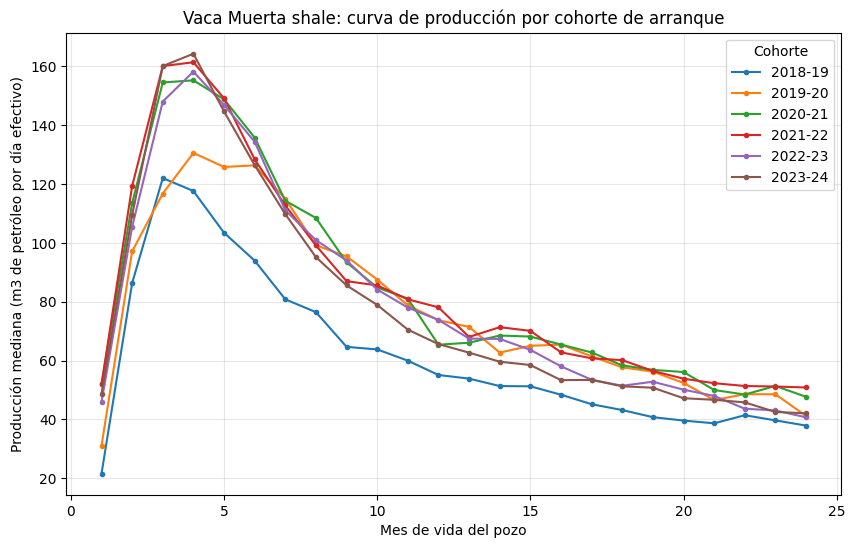

In [58]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

for coh in sorted(curvas["cohorte"].unique()):
    d = curvas[curvas["cohorte"] == coh]
    ax.plot(d["mes_vida"], d["mediana"], marker="o", markersize=3, label=coh)

ax.set_xlabel("Mes de vida del pozo")
ax.set_ylabel("Producción mediana (m3 de petróleo por día efectivo)")
ax.set_title("Vaca Muerta shale: curva de producción por cohorte de arranque")
ax.legend(title="Cohorte")
ax.grid(alpha=0.3)

plt.show()

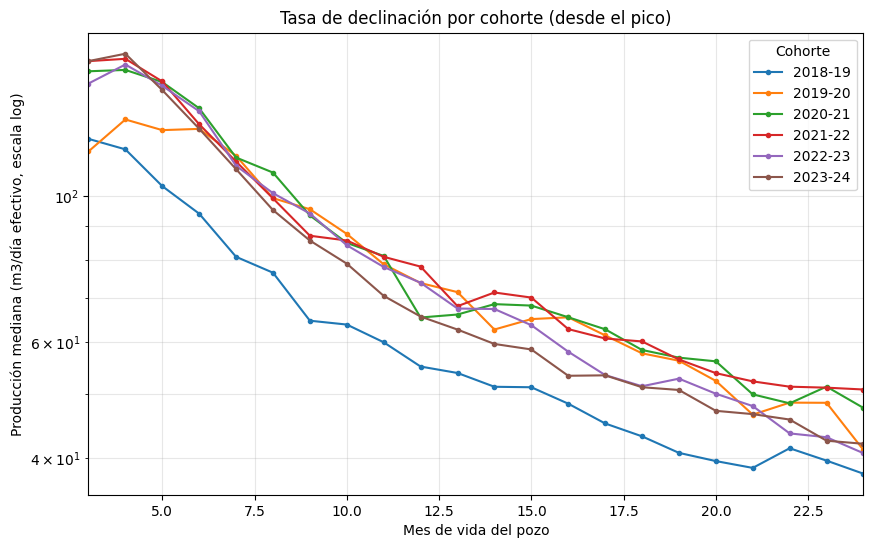

In [59]:
fig, ax = plt.subplots(figsize=(10, 6))

for coh in sorted(curvas["cohorte"].unique()):
    d = curvas[(curvas["cohorte"] == coh) & (curvas["mes_vida"] >= 3)]
    ax.plot(d["mes_vida"], d["mediana"], marker="o", markersize=3, label=coh)

ax.set_yscale("log")
ax.set_xlim(3, 24)
ax.set_xlabel("Mes de vida del pozo")
ax.set_ylabel("Producción mediana (m3/día efectivo, escala log)")
ax.set_title("Tasa de declinación por cohorte (desde el pico)")
ax.legend(title="Cohorte")
ax.grid(alpha=0.3, which="both")

plt.show()

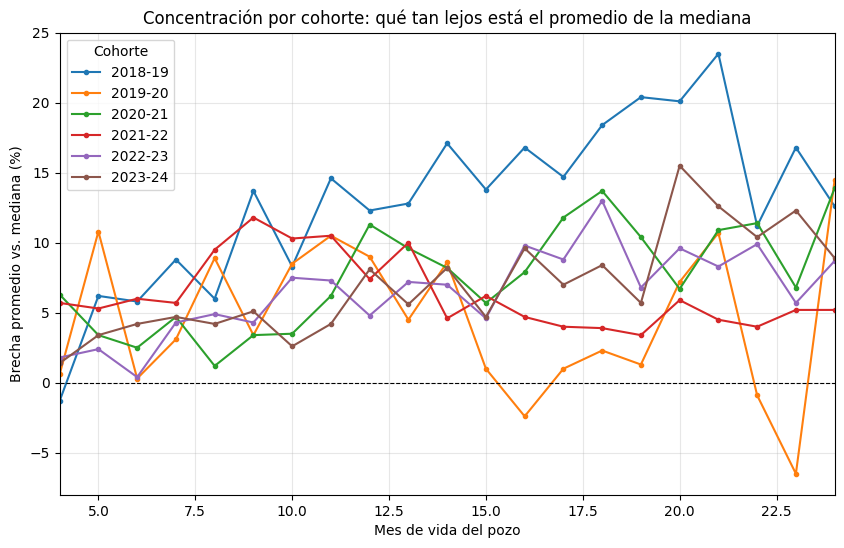

In [60]:
curvas["brecha_%"] = ((curvas["promedio"] - curvas["mediana"]) / curvas["mediana"] * 100).round(1)

fig, ax = plt.subplots(figsize=(10, 6))

for coh in sorted(curvas["cohorte"].unique()):
    d = curvas[(curvas["cohorte"] == coh) & (curvas["mes_vida"] >= 4)]
    ax.plot(d["mes_vida"], d["brecha_%"], marker="o", markersize=3, label=coh)

ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xlim(4, 24)
ax.set_xlabel("Mes de vida del pozo")
ax.set_ylabel("Brecha promedio vs. mediana (%)")
ax.set_title("Concentración por cohorte: qué tan lejos está el promedio de la mediana")
ax.legend(title="Cohorte")
ax.grid(alpha=0.3)

plt.show()

In [61]:
pico = curvas.loc[curvas.groupby("cohorte")["mediana"].idxmax()][["cohorte", "mes_vida", "mediana"]]
pico.columns = ["cohorte", "mes_pico", "val_pico"]

fin = curvas[curvas["mes_vida"] == 24][["cohorte", "mediana", "pozos"]]
fin.columns = ["cohorte", "val_24", "pozos_24"]

comp = pico.merge(fin, on="cohorte")
comp["caida_%"] = ((1 - comp["val_24"] / comp["val_pico"]) * 100).round(1)

print(comp.round(1))

   cohorte  mes_pico  val_pico  val_24  pozos_24  caida_%
0  2018-19       3.0     122.0    37.9       108     69.0
1  2019-20       4.0     130.6    41.1        77     68.5
2  2020-21       4.0     155.3    47.7       131     69.3
3  2021-22       4.0     161.4    50.8       178     68.5
4  2022-23       4.0     158.3    40.7       218     74.3
5  2023-24       4.0     164.3    42.0       315     74.4


In [62]:
fin3 = (curvas[curvas["mes_vida"].between(22, 24)]
        .groupby("cohorte")["mediana"].mean().round(1))

comp2 = comp[["cohorte", "val_pico", "val_24", "caida_%"]].merge(
    fin3.rename("prom_22_24"), on="cohorte")
comp2["caida_prom_%"] = ((1 - comp2["prom_22_24"] / comp2["val_pico"]) * 100).round(1)

print(comp2.round(1))

   cohorte  val_pico  val_24  caida_%  prom_22_24  caida_prom_%
0  2018-19     122.0    37.9     69.0        39.6          67.6
1  2019-20     130.6    41.1     68.5        46.1          64.7
2  2020-21     155.3    47.7     69.3        49.1          68.4
3  2021-22     161.4    50.8     68.5        51.1          68.3
4  2022-23     158.3    40.7     74.3        42.4          73.2
5  2023-24     164.3    42.0     74.4        43.4          73.6


In [63]:
print(oil[oil["mes_vida"].between(10, 14)]
      .groupby("anio")["pet_dia"].agg(["median", "count"]).round(1))

      median  count
anio               
2019    51.2    206
2020    65.3    562
2021    78.6    371
2022    73.9    890
2023    79.2   1042
2024    66.6   1186
2025    64.4    995


In [64]:
tabla = oil.pivot_table(index="mes_vida", columns="anio",
                        values="pet_dia", aggfunc="median").round(0)

print(tabla.loc[8:16])

anio      2018  2019  2020   2021   2022   2023  2024  2025  2026
mes_vida                                                         
8.0        NaN  75.0  94.0  106.0  102.0  108.0  95.0  92.0   NaN
9.0        NaN  55.0  89.0  103.0   87.0   95.0  84.0  87.0   NaN
10.0       NaN  63.0  73.0   92.0   82.0   86.0  77.0  81.0   NaN
11.0       NaN  48.0  71.0   85.0   81.0   84.0  65.0  73.0   NaN
12.0       NaN  43.0  62.0   76.0   74.0   79.0  64.0  64.0   NaN
13.0       NaN  49.0  60.0   71.0   69.0   75.0  64.0  61.0   NaN
14.0       NaN  50.0  56.0   68.0   70.0   73.0  64.0  58.0   NaN
15.0       NaN  44.0  53.0   67.0   68.0   70.0  64.0  57.0   NaN
16.0       NaN  47.0  47.0   67.0   66.0   64.0  58.0  52.0   NaN


In [65]:
viejos = vm[vm["arranque"].notna() & (vm["arranque"] < "2018-09-01")].copy()

print("pozos:", viejos["idpozo"].nunique())
print("filas:", len(viejos))
print()
print(viejos["anio"].value_counts().sort_index())

pozos: 889
filas: 122668

anio
2006     1199
2007     1211
2008      878
2009      132
2010      189
2011      287
2012      748
2013     1620
2014     3771
2015     5767
2016     7536
2017     8762
2018    10275
2019    10581
2020    10591
2021    10596
2022    10603
2023    10589
2024    10563
2025    10596
2026     6174
Name: count, dtype: int64


In [66]:
t_v = viejos[viejos["mes_vida"].between(1, 24)].groupby("idpozo")[["prod_pet", "prod_gas"]].sum()
t_v["m3_m3"] = np.where(t_v["prod_pet"] > 0, t_v["prod_gas"] / t_v["prod_pet"] * 1000, np.inf)

pet_viejos = t_v[t_v["m3_m3"] < 2672].index
ctrl = viejos[viejos["idpozo"].isin(pet_viejos)].copy()
ctrl["pet_dia"] = ctrl["prod_pet"] / ctrl["tef"].replace(0, np.nan)

print("pozos de control petroleros:", ctrl["idpozo"].nunique(), "de 889")
print("filas:", len(ctrl))

pozos de control petroleros: 705 de 889
filas: 100633


In [67]:
serie = ctrl[ctrl["anio"].between(2019, 2025)].groupby("anio")["pet_dia"].agg(["median", "count"]).round(1)
serie["var_%"] = (serie["median"].pct_change() * 100).round(1)

print(serie)

      median  count  var_%
anio                      
2019     2.2   7297    NaN
2020     1.9   6667  -13.6
2021     1.6   6572  -15.8
2022     1.7   5980    6.2
2023     1.4   5892  -17.6
2024     1.3   5760   -7.1
2025     1.2   5741   -7.7


In [68]:
c = ctrl[ctrl["anio"].between(2019, 2025)]

print("filas con pet_dia == 0:", (c["pet_dia"] == 0).sum(), "de", c["pet_dia"].notna().sum())
print()
print(c[c["pet_dia"] > 0].groupby("anio")["pet_dia"].agg(
    ["count", "median", lambda s: s.quantile(0.75)]).round(1))

filas con pet_dia == 0: 275 de 43909

      count  median  <lambda_0>
anio                           
2019   7265     2.2        11.4
2020   6630     1.9        10.7
2021   6529     1.6         9.1
2022   5938     1.7         8.3
2023   5852     1.4         6.9
2024   5720     1.3         6.6
2025   5700     1.2         7.1


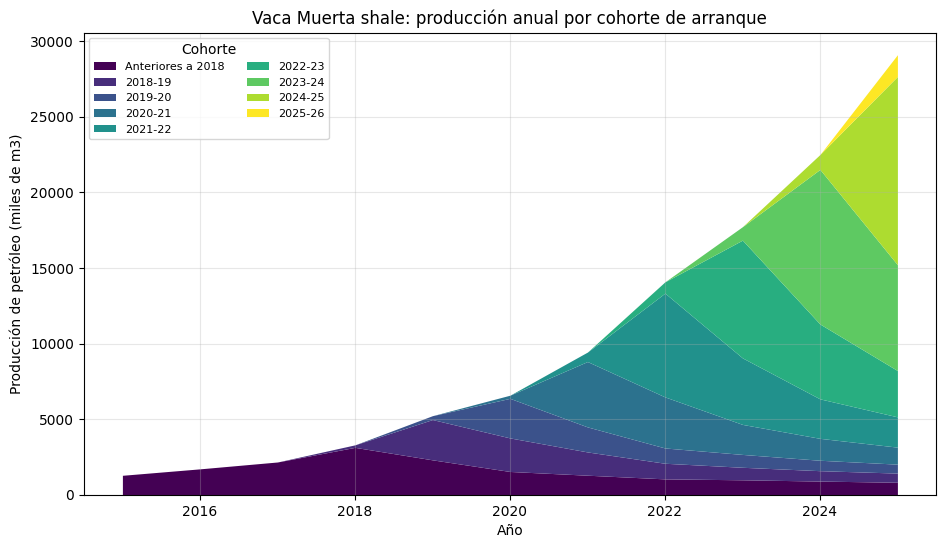

pozos en el gráfico: 3012


In [72]:
todo = vm[vm["arranque"].notna()].copy()
todo["coh"] = todo["anio_cohorte"].apply(
    lambda a: "Anteriores a 2018" if a < 2018 else f"{int(a)}-{str(int(a)+1)[2:]}")

pt = (todo[todo["anio"].between(2015, 2025)]
      .pivot_table(index="anio", columns="coh", values="prod_pet", aggfunc="sum")
      .fillna(0) / 1000)

orden = ["Anteriores a 2018"] + sorted([c for c in pt.columns if c != "Anteriores a 2018"])
pt = pt[orden]

fig, ax = plt.subplots(figsize=(11, 6))
pt.plot(kind="area", stacked=True, ax=ax, linewidth=0, colormap="viridis")

ax.set_xlabel("Año")
ax.set_ylabel("Producción de petróleo (miles de m3)")
ax.set_title("Vaca Muerta shale: producción anual por cohorte de arranque")
ax.legend(title="Cohorte", ncol=2, fontsize=8)
ax.grid(alpha=0.3)

plt.show()

print("pozos en el gráfico:", todo[todo["anio"].between(2015, 2025)]["idpozo"].nunique())

In [70]:
cand = vm[vm["arranque"].notna()
          & (vm["arranque"] >= "2016-01-01")
          & (vm["arranque"] < "2018-09-01")].copy()

act = cand[cand["anio"].between(2021, 2025)].groupby("idpozo")["tef"].apply(lambda s: (s > 0).mean())
vivos = act[act > 0.8].index

print("candidatos:", cand["idpozo"].nunique())
print("con >80% de meses abiertos entre 2021 y 2025:", len(vivos))

candidatos: 327
con >80% de meses abiertos entre 2021 y 2025: 185


In [71]:
tc = cand[cand["mes_vida"].between(1, 24)].groupby("idpozo")[["prod_pet", "prod_gas"]].sum()
tc["m3_m3"] = np.where(tc["prod_pet"] > 0, tc["prod_gas"] / tc["prod_pet"] * 1000, np.inf)
pet_ctrl = tc[tc["m3_m3"] < 2672].index

ctrl2 = cand[cand["idpozo"].isin(vivos) & cand["idpozo"].isin(pet_ctrl)].copy()
ctrl2["pet_dia"] = ctrl2["prod_pet"] / ctrl2["tef"].replace(0, np.nan)

s2 = ctrl2[ctrl2["anio"].between(2021, 2025)].groupby("anio")["pet_dia"].agg(["median", "count"]).round(1)
s2["var_%"] = (s2["median"].pct_change() * 100).round(1)

print("pozos de control:", ctrl2["idpozo"].nunique())
print()
print(s2)

pozos de control: 111

      median  count  var_%
anio                      
2021    15.4   1288    NaN
2022    14.7   1185   -4.5
2023    14.7   1232    0.0
2024    12.5   1250  -15.0
2025    11.3   1260   -9.6
